In [12]:
import pyC2C as c2c
import matplotlib.pyplot as plt
import pandas as pd

### Load data

In [ ]:
raw_data = pd.read_csv('sample_data/flowmod_C2C005_FID.csv', sep=',', names=['RT', 'FID'])
raw_data.head()

,RT,FID
0,0.000326,2.407383
1,0.000659,2.407063
2,0.000993,2.405869
3,0.001326,2.404210
4,0.001659,2.402816


In [ ]:
results_df = pd.read_csv('sample_data/Flow_C2C-005_results.csv', sep=',')
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z) NO,CNum (m/z) Aromates,CNum (m/z) Hydrocarbons,LRI,DBE,CNum (RT)
0,15.775659,15.73,0.02,133.171699,1,53.014:5.84 54.009:10.52 55.055:66.5 57.07:37....,285.279,-1,-1,-1,-1,1,-1
1,16.043993,16.00,0.12,124.874161,1,53.013:10.66 54.009:8.26 55.055:61.12 57.071:3...,285.280,-1,-1,-1,-1,0,4
2,16.581326,16.53,0.36,158.873007,1,53.013:8.69 54.009:8.82 55.054:63.09 57.07:37....,285.280,-1,-1,-1,-1,0,5
3,17.113993,17.07,0.32,257.106999,1,53.014:35.22 54.009:8.29 55.029:10.3 55.055:26...,271.264,-1,-1,-1,-1,2,-1
4,17.580326,17.53,0.30,59.976025,1,55.055:7.0 59.049:100.0,59.049,-1,-1,-1,-1,2,-1


### Get score from specific fragments

In [22]:
fragment_dict = c2c.dictionaries.fragments_iltp

display(fragment_dict)

{'O': [86, 100, 114, 128, 142, 156, 170, 184, 198],
 'A': [77, 78, 79, 91, 93, 105, 107],
 'DBE 2 3': [81, 95, 109, 123, 137, 151],
 'DBE 5': [111, 125, 139, 153]}

In [23]:
score_dict = c2c.resultsProcessing.fragments_in_scans(results_df, fragment_dict=fragment_dict)

# append scores to results data frame
for cl in score_dict.keys():
    results_df[cl] = score_dict[cl]

results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z) NO,CNum (m/z) Aromates,CNum (m/z) Hydrocarbons,LRI,DBE,CNum (RT),O,A,DBE 2 3,DBE 5
0,15.775659,15.73,0.02,133.171699,1,53.014:5.84 54.009:10.52 55.055:66.5 57.07:37....,285.279,-1,-1,-1,-1,1,-1,0.00,21.15,24.99,15.03
1,16.043993,16.00,0.12,124.874161,1,53.013:10.66 54.009:8.26 55.055:61.12 57.071:3...,285.280,-1,-1,-1,-1,0,4,6.27,5.55,22.16,13.54
2,16.581326,16.53,0.36,158.873007,1,53.013:8.69 54.009:8.82 55.054:63.09 57.07:37....,285.280,-1,-1,-1,-1,0,5,5.95,13.64,22.65,20.52
3,17.113993,17.07,0.32,257.106999,1,53.014:35.22 54.009:8.29 55.029:10.3 55.055:26...,271.264,-1,-1,-1,-1,2,-1,0.00,0.00,6.11,8.03
4,17.580326,17.53,0.30,59.976025,1,55.055:7.0 59.049:100.0,59.049,-1,-1,-1,-1,2,-1,0.00,0.00,0.00,0.00


In [24]:
# get score
first_score_colindex = 13
last_score_colindex = 16

results_df['Class'] = results_df.iloc[:, first_score_colindex:last_score_colindex+1].idxmax(axis=1)
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z) NO,CNum (m/z) Aromates,CNum (m/z) Hydrocarbons,LRI,DBE,CNum (RT),O,A,DBE 2 3,DBE 5,Class
0,15.775659,15.73,0.02,133.171699,1,53.014:5.84 54.009:10.52 55.055:66.5 57.07:37....,285.279,-1,-1,-1,-1,1,-1,0.00,21.15,24.99,15.03,DBE 2 3
1,16.043993,16.00,0.12,124.874161,1,53.013:10.66 54.009:8.26 55.055:61.12 57.071:3...,285.280,-1,-1,-1,-1,0,4,6.27,5.55,22.16,13.54,DBE 2 3
2,16.581326,16.53,0.36,158.873007,1,53.013:8.69 54.009:8.82 55.054:63.09 57.07:37....,285.280,-1,-1,-1,-1,0,5,5.95,13.64,22.65,20.52,DBE 2 3
3,17.113993,17.07,0.32,257.106999,1,53.014:35.22 54.009:8.29 55.029:10.3 55.055:26...,271.264,-1,-1,-1,-1,2,-1,0.00,0.00,6.11,8.03,DBE 5
4,17.580326,17.53,0.30,59.976025,1,55.055:7.0 59.049:100.0,59.049,-1,-1,-1,-1,2,-1,0.00,0.00,0.00,0.00,O


### Scatter plot

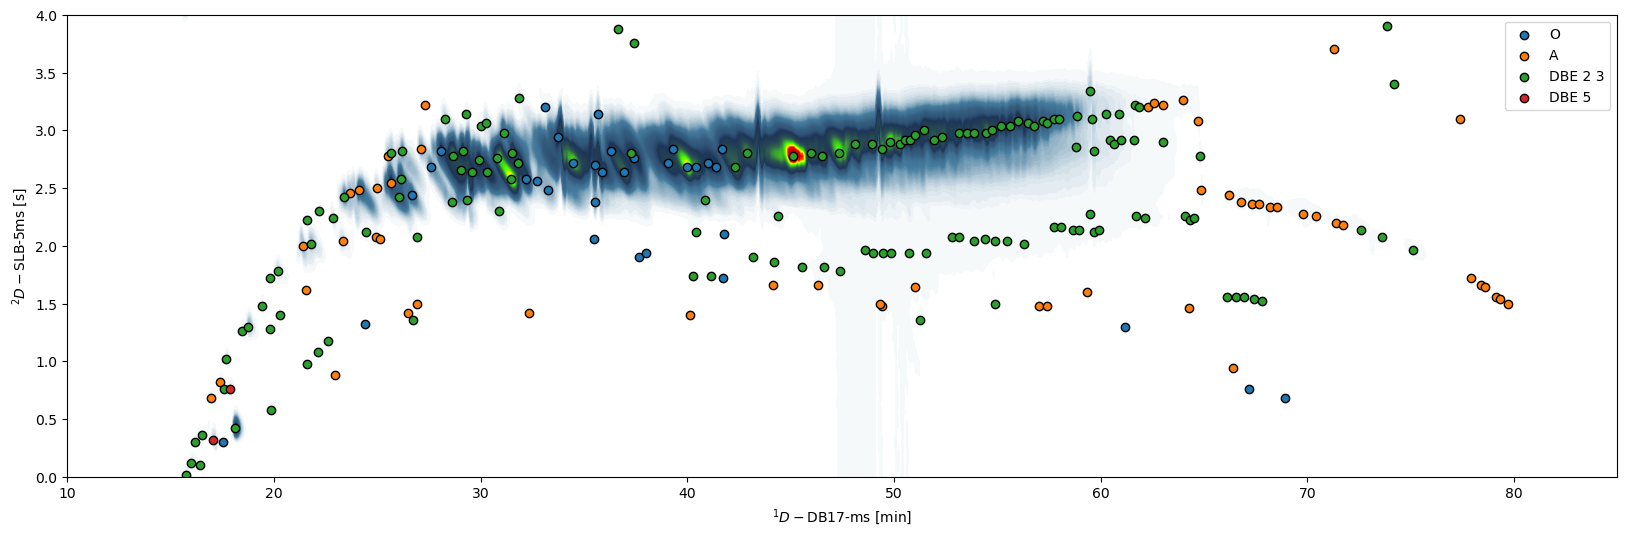

In [25]:
# scatter plot with raw data

fig, ax = plt.subplots(figsize=(20, 6))

xmin = 10
xmax = 85
ymin = 0
ymax = 4

c2c.plot2d(fig, ax,
           raw_data['RT'].values, raw_data['FID'].values,
           mod_time=4, shift= 1.5, solvent_cut= 0,
           color_range=(0, 90), axis_labels=('DB17-ms', 'SLB-5ms'),
           cbar=False)

for cl in fragment_dict.keys():
    sub_df = results_df[results_df['Class'] == cl]

    if len(sub_df) > 0 :
        ax.scatter(sub_df['RT 1d (min)'], sub_df['RT 2d (s)'], label=cl, edgecolors='black')

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.legend()

plt.show()

In [ ]:
# export data frame
results_df.to_csv('sample_data/Flow_C2C-005_results.csv', sep=',', index=False)